# Chapitre 3 - Exercices 3.1 à 3.5

Ces exercices portent sur l'inférence dans le modèle linéaire (tests $Z$ et $F$, bandes de
confiance), le théorème de Gauss–Markov, le calcul des moindres carrés par Gram–Schmidt et
le rôle de l'ordonnée à l'origine dans ridge et le lasso.

Notations (cours 1) : $\mathbf{X}$ est la matrice $N\times(p+1)$ des entrées (première
colonne de uns), $\hat\beta = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$,
$\hat\sigma^2 = \mathrm{RSS}/(N-p-1)$, et $v_j$ le $j$-ième élément diagonal de
$(\mathbf{X}^T\mathbf{X})^{-1}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

import pandas as pd
from scipy import stats
from sklearn.linear_model import Lasso, Ridge
from esl import ch03_regression as cr

Xtr, ytr, Xte, yte, names = cr.load_prostate_standardized()

## Exercice 3.1 : Statistique $F$ et score $Z$

**Énoncé.** Montrer que la statistique $F$ (éq. (3.13)) associée au retrait d'**un seul**
coefficient du modèle est égale au carré du score $Z$ correspondant (éq. (3.12)).

**Rappels.** Pour un gros modèle à $p_1+1$ paramètres et un petit modèle emboîté à $p_0+1$
paramètres,

$$
F = \frac{(\mathrm{RSS}_0 - \mathrm{RSS}_1)/(p_1 - p_0)}{\mathrm{RSS}_1/(N - p_1 - 1)},
\qquad
z_j = \frac{\hat\beta_j}{\hat\sigma\sqrt{v_j}} .
$$

Ici $p_1 = p$, $p_0 = p - 1$, et le dénominateur de $F$ vaut $\hat\sigma^2$ (estimé dans le
gros modèle). Il suffit donc de prouver

$$
\mathrm{RSS}_0 - \mathrm{RSS}_1 = \frac{\hat\beta_j^2}{v_j}.
$$

**Étape 1 : la baisse de RSS due à $\mathbf{x}_j$.** Quitte à renuméroter, plaçons
$\mathbf{x}_j$ en **dernier**. Notons $\mathbf{X}_0$ la matrice sans $\mathbf{x}_j$ et
$\mathbf{z}_j = \mathbf{x}_j - \mathbf{H}_0\mathbf{x}_j$ le résidu de la régression de
$\mathbf{x}_j$ sur les autres colonnes ($\mathbf{H}_0$ = projecteur sur $\mathrm{col}(\mathbf{X}_0)$).
Alors $\mathrm{col}(\mathbf{X}) = \mathrm{col}(\mathbf{X}_0) \oplus \mathrm{vect}(\mathbf{z}_j)$,
somme **orthogonale** ($\mathbf{z}_j \perp \mathrm{col}(\mathbf{X}_0)$). Le projecteur sur une
somme orthogonale est la somme des projecteurs :

$$
\mathbf{H} = \mathbf{H}_0 + \frac{\mathbf{z}_j\mathbf{z}_j^T}{\lVert\mathbf{z}_j\rVert^2}.
$$

Comme $\mathrm{RSS} = \lVert(\mathbf{I} - \mathbf{H})\mathbf{y}\rVert^2 = \mathbf{y}^T(\mathbf{I} - \mathbf{H})\mathbf{y}$
(projecteur symétrique idempotent), on obtient

$$
\mathrm{RSS}_0 - \mathrm{RSS}_1 = \mathbf{y}^T(\mathbf{H} - \mathbf{H}_0)\mathbf{y}
  = \frac{\langle\mathbf{z}_j, \mathbf{y}\rangle^2}{\lVert\mathbf{z}_j\rVert^2}.
$$

**Étape 2 : lien avec $\hat\beta_j$ et $v_j$.** D'après l'éq. (3.28) (algorithme 3.1),
$\hat\beta_j = \langle\mathbf{z}_j, \mathbf{y}\rangle/\lVert\mathbf{z}_j\rVert^2$, et
d'après l'éq. (3.29), $\mathrm{Var}(\hat\beta_j) = \sigma^2/\lVert\mathbf{z}_j\rVert^2$. Or
l'éq. (3.8) donne aussi $\mathrm{Var}(\hat\beta_j) = \sigma^2 v_j$ ; donc
$v_j = 1/\lVert\mathbf{z}_j\rVert^2$. Ainsi

$$
\frac{\langle\mathbf{z}_j, \mathbf{y}\rangle^2}{\lVert\mathbf{z}_j\rVert^2}
  = \hat\beta_j^2\,\lVert\mathbf{z}_j\rVert^2 = \frac{\hat\beta_j^2}{v_j}.
$$

**Conclusion.**

$$
F = \frac{\hat\beta_j^2/v_j}{\hat\sigma^2} = \Bigl(\frac{\hat\beta_j}{\hat\sigma\sqrt{v_j}}\Bigr)^2 = z_j^2. \qquad\square
$$

C'est cohérent avec les lois : si $T \sim t_k$, alors $T^2 \sim F_{1,k}$.

**Vérification numérique** sur la prostate : pour chaque variable, on ajuste le modèle sans
elle et l'on compare $F$ à $z_j^2$.

In [2]:
full = cr.ols_fit(Xtr, ytr)
rows = []
for j in range(8):
    keep = [k for k in range(8) if k != j]
    F, pval = cr.f_test(cr.ols_fit(Xtr[:, keep], ytr)["rss"], full["rss"], 7, 8, len(ytr))
    rows.append((full["z"][j + 1] ** 2, F, pval, 2 * stats.t(full["df_resid"]).sf(abs(full["z"][j + 1]))))
pd.DataFrame(rows, index=names, columns=["z_j^2", "F", "p-valeur (F)", "p-valeur (t)"]).round(4)

,z_j^2,F,p-valeur (F),p-valeur (t)
lcavol,28.7971,28.7971,0.0000,0.0000
lweight,7.5668,7.5668,0.0079,0.0079
age,1.9486,1.9486,0.1681,0.1681
lbph,4.2265,4.2265,0.0443,0.0443
svi,6.0972,6.0972,0.0165,0.0165
lcp,3.4854,3.4854,0.0670,0.0670
gleason,0.0215,0.0215,0.8839,0.8839
pgg45,3.0201,3.0201,0.0875,0.0875


Les deux statistiques et les deux p-valeurs coïncident exactement.

> **À retenir.** Retirer un coefficient augmente le RSS de $\hat\beta_j^2/v_j = z_j^2\hat\sigma^2$ ;
> le test $F$ à un degré de liberté et le test $t$ bilatéral sont le même test.

## Exercice 3.2 : Bandes de confiance pour une régression cubique

**Énoncé.** On ajuste un polynôme de degré 3, $f(X) = \sum_{j=0}^3\beta_jX^j$, à des données
$(x_i, y_i)$, et l'on veut une bande de confiance à 95 % autour de la courbe. Deux approches :

1. en chaque point $x_0$, un intervalle de confiance à 95 % pour la fonction linéaire
   $a^T\beta = \sum_{j=0}^3\beta_jx_0^j$ ;
2. une région de confiance à 95 % pour $\beta$ (éq. (3.15)), qui induit des intervalles
   pour $f(x_0)$.

En quoi ces approches diffèrent-elles ? Laquelle donne la bande la plus large ? Comparer
par une petite simulation.

**Approche 1 (ponctuelle).** Posons $a = (1, x_0, x_0^2, x_0^3)^T$. Comme
$\hat\beta \sim \mathcal{N}(\beta, (\mathbf{X}^T\mathbf{X})^{-1}\sigma^2)$, on a
$a^T\hat\beta \sim \mathcal{N}\bigl(a^T\beta,\ \sigma^2 a^T(\mathbf{X}^T\mathbf{X})^{-1}a\bigr)$,
d'où l'intervalle

$$
a^T\hat\beta \pm z^{(0{,}975)}\,\hat\sigma\sqrt{a^T(\mathbf{X}^T\mathbf{X})^{-1}a},
\qquad z^{(0{,}975)} = 1{,}96 .
$$

(Avec $N$ modéré on peut remplacer $1{,}96$ par le quantile de $t_{N-4}$.)

**Approche 2 (via la région pour $\beta$).** La région (3.15) est l'ellipsoïde
$C_\beta = \{\beta : (\beta - \hat\beta)^T\mathbf{X}^T\mathbf{X}(\beta - \hat\beta) \le \hat\sigma^2 c\}$
avec $c = \chi^{2\,(0{,}95)}_4 = 9{,}49$. L'intervalle induit pour $f(x_0) = a^T\beta$ est
$[\min_{C_\beta} a^T\beta,\ \max_{C_\beta} a^T\beta]$.

Calculons ce maximum. Posons $\mathbf{A} = \mathbf{X}^T\mathbf{X}$ (symétrique définie
positive, donc possède une racine carrée $\mathbf{A}^{1/2}$) et
$\mathbf{u} = \mathbf{A}^{1/2}(\beta - \hat\beta)$ : la contrainte devient
$\lVert\mathbf{u}\rVert^2 \le \hat\sigma^2 c$, et
$a^T(\beta - \hat\beta) = (\mathbf{A}^{-1/2}a)^T\mathbf{u}$.

Par l'inégalité de Cauchy–Schwarz,
$(\mathbf{A}^{-1/2}a)^T\mathbf{u} \le \lVert\mathbf{A}^{-1/2}a\rVert\,\lVert\mathbf{u}\rVert \le \sqrt{a^T\mathbf{A}^{-1}a}\ \hat\sigma\sqrt{c}$,
avec égalité pour $\mathbf{u}$ colinéaire à $\mathbf{A}^{-1/2}a$. D'où l'intervalle

$$
a^T\hat\beta \pm \sqrt{\chi^{2\,(0{,}95)}_4}\ \hat\sigma\sqrt{a^T(\mathbf{X}^T\mathbf{X})^{-1}a}.
$$

**Comparaison.** Les deux bandes ont la même forme ; seul le facteur change :
$\sqrt{9{,}49} = 3{,}08$ contre $1{,}96$. La bande 2 est **plus large**, d'un facteur
$3{,}08/1{,}96 \approx 1{,}57$ à chaque $x_0$.

**Interprétation.** Les deux bandes ne garantissent pas la même chose :
- la bande 1 contient $f(x_0)$ avec probabilité 95 % **pour chaque $x_0$ pris
  isolément** (couverture ponctuelle) ; la probabilité que la courbe entière soit dans la
  bande est plus faible ;
- la bande 2 contient la courbe **entière** dès que $\beta \in C_\beta$, ce qui arrive avec
  probabilité 95 % : c'est une bande **simultanée** (et même conservatrice, car elle
  protège contre toutes les combinaisons $a^T\beta$, pas seulement les polynômes en $x_0$).

Simulons-le.

In [3]:
rng = np.random.RandomState(0)
N, sigma = 40, 1.0
x = np.sort(rng.uniform(-2, 2, N))
f_true = lambda t: 1 + t - 0.5 * t**2 + 0.3 * t**3
Xpoly = np.vander(x, 4, increasing=True)
x0 = np.linspace(-2, 2, 101)
A0 = np.vander(x0, 4, increasing=True)
XtX_inv = np.linalg.inv(Xpoly.T @ Xpoly)
lever = np.sqrt(np.einsum("ij,jk,ik->i", A0, XtX_inv, A0))     # sqrt(a^T (X^T X)^{-1} a)
k1, k2 = stats.norm.ppf(0.975), np.sqrt(stats.chi2.ppf(0.95, 4))
print("facteurs : approche 1 = %.3f, approche 2 = %.3f, rapport = %.3f" % (k1, k2, k2 / k1))

facteurs : approche 1 = 1.960, approche 2 = 3.080, rapport = 1.572


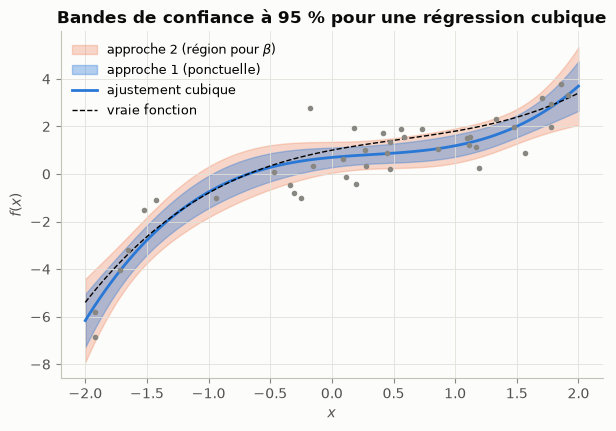

In [4]:
y = f_true(x) + sigma * rng.randn(N)
fit = cr.ols_fit(Xpoly[:, 1:], y)
fhat = A0 @ fit["coef"]
s_hat = np.sqrt(fit["sigma2"])
fig, ax = plt.subplots()
ax.fill_between(x0, fhat - k2 * s_hat * lever, fhat + k2 * s_hat * lever, color=ORANGE, alpha=0.25,
                label=r"approche 2 (région pour $\beta$)")
ax.fill_between(x0, fhat - k1 * s_hat * lever, fhat + k1 * s_hat * lever, color=BLUE, alpha=0.35,
                label="approche 1 (ponctuelle)")
ax.plot(x0, fhat, color=BLUE, label="ajustement cubique")
ax.plot(x0, f_true(x0), color="black", linestyle="--", linewidth=1, label="vraie fonction")
ax.plot(x, y, "o", color=GRAY, markersize=3)
ax.set_title("Bandes de confiance à 95 % pour une régression cubique")
ax.set_xlabel("$x$"); ax.set_ylabel("$f(x)$")
ax.legend()
plt.show()

Répétons l'expérience 2000 fois (même $x$, nouveaux bruits) pour estimer la couverture
**ponctuelle** (en chaque $x_0$) et **simultanée** (toute la courbe dans la bande).

In [5]:
n_sim = 2000
inside1 = np.zeros((n_sim, len(x0)), bool)
inside2 = np.zeros((n_sim, len(x0)), bool)
for b in range(n_sim):
    yb = f_true(x) + sigma * rng.randn(N)
    fb = cr.ols_fit(Xpoly[:, 1:], yb)
    err = np.abs(A0 @ fb["coef"] - f_true(x0))
    half = np.sqrt(fb["sigma2"]) * lever
    inside1[b] = err <= k1 * half
    inside2[b] = err <= k2 * half
print("couverture ponctuelle moyenne : approche 1 = %.3f, approche 2 = %.3f"
      % (inside1.mean(), inside2.mean()))
print("couverture simultanée         : approche 1 = %.3f, approche 2 = %.3f"
      % (inside1.all(1).mean(), inside2.all(1).mean()))

couverture ponctuelle moyenne : approche 1 = 0.944, approche 2 = 0.995
couverture simultanée         : approche 1 = 0.720, approche 2 = 0.965


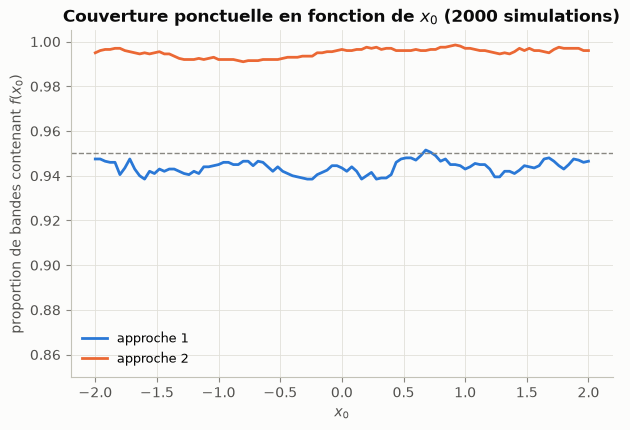

In [6]:
fig, ax = plt.subplots()
ax.plot(x0, inside1.mean(0), color=BLUE, label="approche 1")
ax.plot(x0, inside2.mean(0), color=ORANGE, label="approche 2")
ax.axhline(0.95, color=GRAY, linestyle="--", linewidth=1)
ax.set_ylim(0.85, 1.005)
ax.set_title("Couverture ponctuelle en fonction de $x_0$ (2000 simulations)")
ax.set_xlabel("$x_0$"); ax.set_ylabel("proportion de bandes contenant $f(x_0)$")
ax.legend()
plt.show()

L'approche 1 a une couverture ponctuelle proche de 95 % (un peu moins, car on utilise le
quantile normal avec seulement $N - 4 = 36$ degrés de liberté), mais la courbe entière
n'est dans la bande que dans environ 70 % des cas. L'approche 2 couvre la courbe entière
dans plus de 95 % des cas, au prix d'une bande 1,57 fois plus large.

> **À retenir.** Bande ponctuelle : facteur $z^{(0{,}975)}$ ; bande simultanée déduite de
> l'ellipsoïde de confiance : facteur $\sqrt{\chi^{2\,(0{,}95)}_{p+1}}$, plus large. Le
> choix dépend de la question posée (un point, ou la courbe entière).

## Exercice 3.3 : Théorème de Gauss–Markov

**Énoncé.**
(a) Montrer que l'estimateur des moindres carrés de $a^T\beta$ a une variance inférieure
ou égale à celle de tout autre estimateur linéaire sans biais de $a^T\beta$.
(b) On écrit $\mathbf{B} \preceq \mathbf{A}$ si $\mathbf{A} - \mathbf{B}$ est semi-définie
positive. Montrer que si $\hat{\mathbf{V}}$ est la matrice de variance-covariance de
$\hat\beta$ (moindres carrés) et $\tilde{\mathbf{V}}$ celle de tout autre estimateur
linéaire sans biais de $\beta$, alors $\hat{\mathbf{V}} \preceq \tilde{\mathbf{V}}$.

**Cadre.** $\mathbf{y} = \mathbf{X}\beta + \varepsilon$, $\mathbb{E}\varepsilon = 0$,
$\mathrm{Var}(\varepsilon) = \sigma^2\mathbf{I}$, $\mathbf{X}$ fixe de rang plein.

**(a) Étape 1 : caractériser l'absence de biais.** Un estimateur linéaire s'écrit
$\tilde\theta = c^T\mathbf{y}$ ($c \in \mathbb{R}^N$ fixe). Par linéarité de l'espérance,
$\mathbb{E}\tilde\theta = c^T\mathbf{X}\beta$. Il est sans biais pour $a^T\beta$ **quel que
soit** $\beta$ si et seulement si $c^T\mathbf{X}\beta = a^T\beta$ pour tout $\beta$, c'est-à-dire

$$
\mathbf{X}^Tc = a .
$$

**Étape 2 : décomposer $c$.** L'estimateur des moindres carrés correspond à
$c_0 = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}a$ (éq. (3.17)), qui vérifie bien
$\mathbf{X}^Tc_0 = a$. Pour un $c$ sans biais quelconque, posons $d = c - c_0$ ; alors
$\mathbf{X}^Td = a - a = 0$. Par conséquent

$$
c_0^Td = a^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^Td = 0 .
$$

**Étape 3 : comparer les variances.** $\mathrm{Var}(c^T\mathbf{y}) = c^T(\sigma^2\mathbf{I})c = \sigma^2\lVert c\rVert^2$.
Par Pythagore ($c_0 \perp d$) :

$$
\mathrm{Var}(c^T\mathbf{y}) = \sigma^2\bigl(\lVert c_0\rVert^2 + \lVert d\rVert^2\bigr)
  \ge \sigma^2\lVert c_0\rVert^2 = \mathrm{Var}(a^T\hat\beta),
$$

avec égalité si et seulement si $d = 0$ : l'estimateur des moindres carrés est même
l'**unique** estimateur linéaire sans biais de variance minimale. $\square$

**(b)** Soit $\tilde\beta = \mathbf{C}\mathbf{y}$ un estimateur linéaire sans biais de $\beta$
(donc $\mathbf{C}\mathbf{X} = \mathbf{I}$). Pour tout $a \in \mathbb{R}^{p+1}$, $a^T\tilde\beta = (\mathbf{C}^Ta)^T\mathbf{y}$
est un estimateur linéaire sans biais de $a^T\beta$. D'après (a),

$$
a^T\tilde{\mathbf{V}}a = \mathrm{Var}(a^T\tilde\beta) \ge \mathrm{Var}(a^T\hat\beta) = a^T\hat{\mathbf{V}}a,
$$

(on a utilisé $\mathrm{Var}(a^T\mathbf{w}) = a^T\mathrm{Var}(\mathbf{w})a$). Donc
$a^T(\tilde{\mathbf{V}} - \hat{\mathbf{V}})a \ge 0$ pour tout $a$ : c'est la définition de
$\tilde{\mathbf{V}} - \hat{\mathbf{V}}$ semi-définie positive, i.e.
$\hat{\mathbf{V}} \preceq \tilde{\mathbf{V}}$. $\square$